# COU 07506 Digital Signal Processing Week 01: Setting Up the DSP Laboratory
Name:
Class: BENG24COE
Registration No.:240242426609

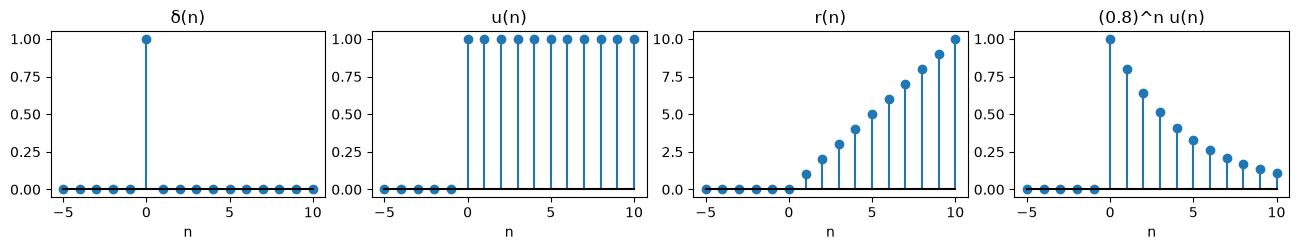

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

# Task 1.1: Elementary sequences
n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step = (n >= 0).astype(float)       # unit step
ramp = n * step                     # unit ramp
expo = (0.8 ** n) * step            # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

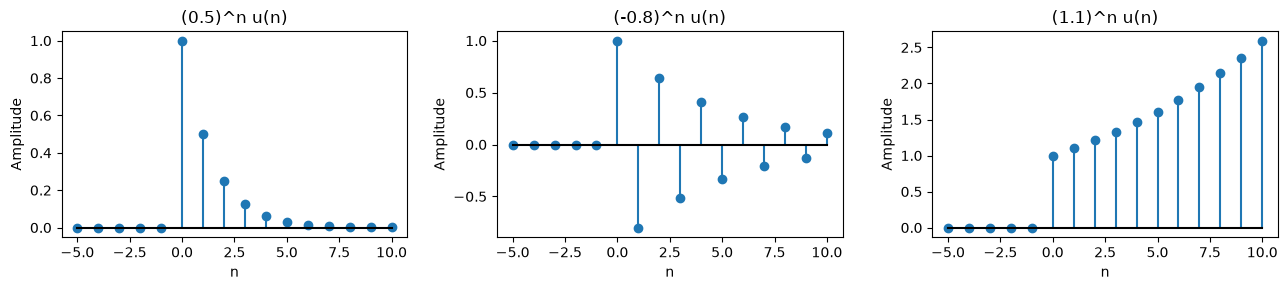

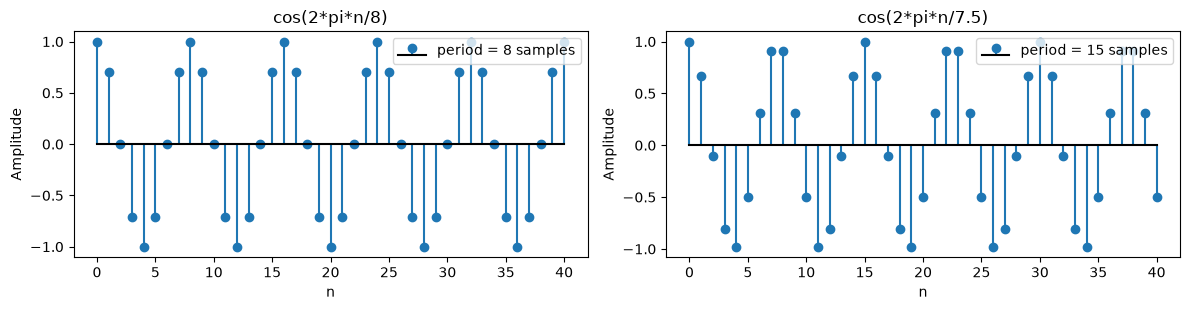

In [3]:
# Task 1.2: Change the parameters

# 1. Plot (a)^n u(n) for a = 0.5, -0.8, and 1.1 on one figure using subplots
n_exp = np.arange(-5, 11)
u_exp = (n_exp >= 0).astype(float)
alphas = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.0))
for ax, a in zip(axes, alphas):
    x_a = (a ** n_exp) * u_exp
    ax.stem(n_exp, x_a, basefmt="k-")
    ax.set_title(f"({a})^n u(n)")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

# 2. Plot cos(2*pi*n/8) and cos(2*pi*n/7.5) for 0 <= n <= 40
n_cos = np.arange(0, 41)
cos_8 = np.cos(2 * np.pi * n_cos / 8)
cos_7_5 = np.cos(2 * np.pi * n_cos / 7.5)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].stem(n_cos, cos_8, basefmt="k-")
axes[0].set_title("cos(2*pi*n/8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].legend(["period = 8 samples"])

axes[1].stem(n_cos, cos_7_5, basefmt="k-")
axes[1].set_title("cos(2*pi*n/7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].legend(["period = 15 samples"])

plt.tight_layout()
plt.show()

fs = 16000 Hz, duration = 2.00 s, samples = 32000


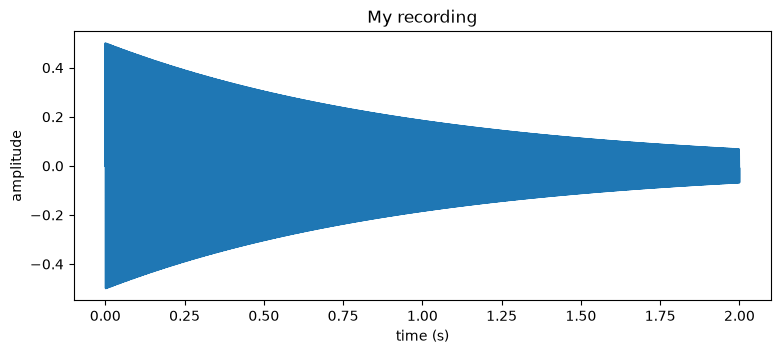

In [4]:
import os
from IPython.display import Audio

# Task 1.3: Working with audio
fname = "my_voice.wav"  # change to your WAV file name if you have one
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)  # stereo -> mono
    x = x / np.max(np.abs(x))  # normalise to [-1, 1]
else:
    fs = 16000
    t = np.arange(0, 2, 1 / fs)  # fallback test signal
    x = 0.5 * np.sin(2 * np.pi * 440 * t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x) / fs:.2f} s, samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

Audio(x, rate=fs)